In this lab, we are going to build a seq2seq model for translating text from English to Catalan, and will eventually visualize the attention patterns discovered by the model.

In [1]:
from __future__ import unicode_literals, print_function, division

import re
import math
import random
import string
import unicodedata
from io import open

import numpy as np

import torch
import torch.nn as nn
from torch import optim
import torch.nn.functional as F

%matplotlib inline
import matplotlib.pyplot as plt
import matplotlib.ticker as ticker

import seaborn as sns

To ensure reproducibility of the experiments, we can set the seed to a fixed number.

In [2]:
seed = 123
np.random.seed(seed)
_ = torch.manual_seed(seed)
_ = torch.cuda.manual_seed(seed)

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")

In [3]:
def plot_attention(attention, xtitle="Keys", ytitle="Queries"):
    """ Plots the attention map."""

    sns.set(rc={'figure.figsize':(12, 8)})
    ax = sns.heatmap(
        attention.detach().cpu(),
        linewidth=0.5,
        cmap="Blues",
        square=True)

    ax.set_yticklabels(ax.get_yticklabels(), rotation=0)
    ax.set_xlabel(xtitle)
    ax.set_ylabel(ytitle)

    plt.show()

In [4]:
class AdditiveAttention(nn.Module):
    """
     Implements the additive attention as proposed in "Neural Machine Translation by Jointly Learning to Align and Translate".
     Args:
         q_dim (int): dimesion of the queries
         k_dim (int): dimesion of the keys
         attn_dim (int): dimension of intermediate vectors

     Inputs: query, key, value
        query (torch.FloatTensor):  Query Tensor   (... x T_q x d_q)
        key (torch.FloatTensor):  Key Tensor     (... x T_k x d_k)
        value (torch.FloatTensor):  Value Tensor   (... x T_v x d_v)

    Returns:
        torch.FloatTensor: Result of the Attention Mechanism  (... x T_q x d_v)
        torch.FloatTensor: Attention map       (... x T_q x T_k)

    """
    def __init__(self, q_dim: int, k_dim: int, attn_dim: int) -> None:
        super(AdditiveAttention, self).__init__()

        # TODO: Create projections of queries and keys
        self.proj_q = nn.Linear(q_dim, attn_dim, bias=False)
        self.proj_k = nn.Linear(k_dim, attn_dim, bias=False)

        self.bias = nn.Parameter(torch.rand(attn_dim).uniform_(-0.1, 0.1))
        self.w = nn.Linear(attn_dim, 1)

    def forward(self, query, key, value):
        q_ = self.proj_q(query) # (... x T_q x q_dim) -> (... x T_q x attn_dim)
        k_ = self.proj_k(key)   # (... x T_k x k_dim) -> (... x T_k x attn_dim)

        # Prepare for Broadcasting Semantics
        q_ = q_.unsqueeze(-2)   # (... x T_q x attn_dim) -> (... x T_q x  1  x attn_dim)
        k_ = k_.unsqueeze(-3)   # (... x T_k x attn_dim) -> (... x  1  x T_k x attn_dim)

        # Sum thanks to Broadcasting Semantics
        attn_hid = torch.tanh(q_ + k_ + self.bias) # (... x T_q x  1  x attn_dim) + (... x  1  x T_k x attn_dim) + (attn_dim) -> (... x T_q x T_k x attn_dim)

        attn_logits = self.w(attn_hid)        # (... x T_q x T_k x attn_dim) -> (... x T_q x T_k x 1)
        attn_logits = attn_logits.squeeze(-1) # (... x T_q x T_k x 1) -> (... x T_q x T_k)

        attn_weights = F.softmax(attn_logits, dim=-1)

        # TODO: Compute the output of the attention
        output = torch.matmul(attn_weights, value)

        return output, attn_weights

## Download dataset

In [5]:
!wget http://www.manythings.org/anki/cat-eng.zip
!unzip cat-eng.zip && rm cat-eng.zip
!mkdir data
!mv "cat.txt" "data/eng-cat.txt"

--2026-09-29 07:32:10--  http://www.manythings.org/anki/cat-eng.zip
Resolving www.manythings.org (www.manythings.org)... 173.254.30.110
Connecting to www.manythings.org (www.manythings.org)|173.254.30.110|:80... connected.
HTTP request sent, awaiting response... 200 OK
Length: 66507 (65K) [application/zip]
Saving to: ‘cat-eng.zip’

cat-eng.zip         100%[===================>]  64.95K   190KB/s    in 0.3s    

2026-09-29 07:32:13 (190 KB/s) - ‘cat-eng.zip’ saved [66507/66507]

Archive:  cat-eng.zip
  inflating: _about.txt              
  inflating: cat.txt                 


In [6]:
SOS_token = 0
EOS_token = 1

class Lang:
    def __init__(self, name):
        self.name = name
        self.word2index = {}
        self.word2count = {}
        self.index2word = {0: "SOS", 1: "EOS"}
        self.n_words = 2  # Count SOS and EOS

    def addSentence(self, sentence):
        for word in sentence.split(' '):
            self.addWord(word)

    def addWord(self, word):
        if word not in self.word2index:
            self.word2index[word] = self.n_words
            self.word2count[word] = 1
            self.index2word[self.n_words] = word
            self.n_words += 1
        else:
            self.word2count[word] += 1

## Data pre-processing

First we need to pre-process the raw text data. We need to make sure to lowercase all of it, remove all non-letter characters, and limit the maximum lenght of the sentences to MAX_LENGTH. Eventually, we create ```pairs```, a list where each component has a sentence and its translation, both pre-processed.



In [7]:
# Turn a Unicode string to plain ASCII, thanks to
# http://stackoverflow.com/a/518232/2809427
def unicodeToAscii(s):
    return ''.join(
        c for c in unicodedata.normalize('NFD', s)
        if unicodedata.category(c) != 'Mn'
    )

# Lowercase, trim, and remove non-letter characters
def normalizeString(s):
    s = unicodeToAscii(s.lower().strip())
    s = re.sub(r"([.!?])", r" \1", s)
    s = re.sub(r"[^a-zA-Z.!?]+", r" ", s)
    return s

def readLangs(lang1, lang2, reverse=False):
    print("Reading lines...")

    # Read the file and split into lines
    lines = open('data/%s-%s.txt' % (lang1, lang2), encoding='utf-8').\
        read().strip().split('\n')

    # Remove extra info
    new_lines = []
    for line in lines:
        new_lines.append(line[0:(line.find('CC-BY')-1)])


    # Split every line into pairs and normalize
    pairs = [[normalizeString(s) for s in l.split('\t')] for l in new_lines]

    # Reverse pairs, make Lang instances
    if reverse:
        pairs = [list(reversed(p)) for p in pairs]
        input_lang = Lang(lang2)
        output_lang = Lang(lang1)
    else:
        input_lang = Lang(lang1)
        output_lang = Lang(lang2)

    return input_lang, output_lang, pairs

MAX_LENGTH = 20

def filterPair(p):
    return len(p[0].split(' ')) < MAX_LENGTH and \
        len(p[1].split(' ')) < MAX_LENGTH

def filterPairs(pairs):
    return [pair for pair in pairs if filterPair(pair)]

def prepareData(lang1, lang2, reverse=False):
    input_lang, output_lang, pairs = readLangs(lang1, lang2, reverse)
    print("Read %s sentence pairs" % len(pairs))
    pairs = filterPairs(pairs)
    print("Trimmed to %s sentence pairs" % len(pairs))
    print("Counting words...")
    for pair in pairs:
        input_lang.addSentence(pair[0])
        output_lang.addSentence(pair[1])
    print("Counted words:")
    print(input_lang.name, input_lang.n_words)
    print(output_lang.name, output_lang.n_words)
    return input_lang, output_lang, pairs


input_lang, output_lang, pairs = prepareData('eng', 'cat', False)
print(random.choice(pairs))

Reading lines...
Read 1694 sentence pairs
Trimmed to 1692 sentence pairs
Counting words...
Counted words:
eng 1632
cat 2043
['i don t want to sit alone in the dark .', 'no vull seure sola a la foscor .']


We have a total of 1306 pairs of sentences containing 1436 english words and 1773 catalan words. We use a very small dataset to reduce training time, but a larger dataset would be necessary to learn something meaningful.

## Building the seq2seq model

We proceed to build our seq2seq model with attention. First we define our encoder RNN:

In [8]:
class EncoderRNN(nn.Module):
    def __init__(self, input_size, hidden_size):
        super(EncoderRNN, self).__init__()
        self.hidden_size = hidden_size

        # TODO: Define the Embedding matrix (use nn.Embedding)
        self.embedding = nn.Embedding(input_size, hidden_size)

        self.gru = nn.GRU(hidden_size, hidden_size, batch_first=True)

    def forward(self, input, hidden):
        embedded = self.embedding(input)
        output = embedded
        output, hidden = self.gru(output, hidden)
        return output, hidden

    def initHidden(self):
        return torch.zeros(1, 1, self.hidden_size, device=device)

Now we define our decoder, with an attention mechanism (```self.attn```) built inside. Try to map the code with the following diagram:

<p align="center"><br>
<img src="https://github.com/telecombcn-dl/labs-all/raw/main/labs/attention/images/attention_tensor_dance_last.jpeg?raw=true" class="center" title="Decoding with attention" width="800"/>
</p><br>

In [9]:
class AttnDecoderRNN(nn.Module):
    def __init__(self, hidden_size, output_size, dropout_p=0.1, max_length=MAX_LENGTH):
        super(AttnDecoderRNN, self).__init__()
        self.hidden_size = hidden_size
        self.output_size = output_size
        self.dropout_p = dropout_p
        self.max_length = max_length

        self.embedding = nn.Embedding(self.output_size, self.hidden_size)
        self.gru = nn.GRU(self.hidden_size, self.hidden_size, batch_first=True)
        self.dropout = nn.Dropout(self.dropout_p)
        # Here we define the attention we use
        self.attn = AdditiveAttention(self.hidden_size, self.hidden_size, self.hidden_size // 2)
        #self.attn = MultiplicativeAttention(self.hidden_size, self.hidden_size)
        self.attn_combine = nn.Linear(self.hidden_size * 2, self.hidden_size)
        self.out = nn.Linear(self.hidden_size, self.output_size)

    def forward(self, input, hidden, encoder_outputs):
        embedded = self.embedding(input)
        embedded = self.dropout(embedded)

        x, hidden = self.gru(embedded, hidden)
        context, attn_weights = self.attn(query=x, key=encoder_outputs, value=encoder_outputs)

        # TODO: compute concatenation of the decoder hidden states and the context vectors
        x_w_context = torch.cat((x, context), dim=-1)

        x_w_context = self.attn_combine(x_w_context)
        output = F.log_softmax(self.out(x_w_context), dim=-1)
        return output, hidden, attn_weights

    def initHidden(self):
        return torch.zeros(1, 1, self.hidden_size, device=device)

In [10]:
def indexesFromSentence(lang, sentence):
    return [lang.word2index[word] for word in sentence.split(' ')]


def tensorFromSentence(lang, sentence):
    indexes = indexesFromSentence(lang, sentence)
    indexes.append(EOS_token)
    return torch.tensor(indexes, dtype=torch.long, device=device).view(1, -1)


def tensorsFromPair(pair):
    input_tensor = tensorFromSentence(input_lang, pair[0])
    target_tensor = tensorFromSentence(output_lang, pair[1])
    return (input_tensor, target_tensor)

In [11]:
def train(input_tensor, target_tensor, encoder, decoder, encoder_optimizer, decoder_optimizer, criterion, max_length=MAX_LENGTH):
    encoder_hidden = encoder.initHidden()

    encoder_optimizer.zero_grad()
    decoder_optimizer.zero_grad()

    encoder_outputs, encoder_hidden = encoder(input_tensor, encoder_hidden)

    # First hidden state used by the decoder is the last encoder hidden state
    decoder_hidden = encoder_hidden

    # We feed the decoder with the whole target sentence (teacher forcing),
    # first we append SOS_token
    decoder_input = torch.cat([
        torch.tensor([[SOS_token]], device=device),
        target_tensor[:, :-1]
    ], dim=1)


    decoder_output, decoder_hidden, decoder_attention = decoder(
                decoder_input, decoder_hidden, encoder_outputs)

    loss = criterion(
        decoder_output.view(-1, decoder_output.size(-1)),
        target_tensor.view(-1)
    )
    loss.backward()

    encoder_optimizer.step()
    decoder_optimizer.step()

    return loss.item() / target_tensor.numel()

In [12]:
import time

def asMinutes(s):
    m = math.floor(s / 60)
    s -= m * 60
    return '%dm %ds' % (m, s)


def timeSince(since, percent):
    now = time.time()
    s = now - since
    es = s / (percent)
    rs = es - s
    return '%s (- %s)' % (asMinutes(s), asMinutes(rs))

def showPlot(points):
    plt.figure()
    fig, ax = plt.subplots()
    # this locator puts ticks at regular intervals
    loc = ticker.MultipleLocator(base=0.2)
    ax.yaxis.set_major_locator(loc)
    plt.plot(points)

In [13]:
def trainIters(encoder, decoder, n_iters, print_every=1000, plot_every=100, learning_rate=0.01):
    start = time.time()
    plot_losses = []
    print_loss_total = 0  # Reset every print_every
    plot_loss_total = 0  # Reset every plot_every

    encoder_optimizer = optim.SGD(encoder.parameters(), lr=learning_rate)
    decoder_optimizer = optim.SGD(decoder.parameters(), lr=learning_rate)

    # Random sample of n_iters pairs
    training_pairs = [tensorsFromPair(random.choice(pairs))
                      for i in range(n_iters)]
    criterion = nn.NLLLoss()

    for iter in range(1, n_iters + 1):
        training_pair = training_pairs[iter - 1]
        input_tensor = training_pair[0]
        target_tensor = training_pair[1]

        loss = train(input_tensor, target_tensor, encoder,
                     decoder, encoder_optimizer, decoder_optimizer, criterion)
        print_loss_total += loss
        plot_loss_total += loss

        if iter % print_every == 0:
            print_loss_avg = print_loss_total / print_every
            print_loss_total = 0
            print('%s (%d %d%%) %.4f' % (timeSince(start, iter / n_iters),
                                         iter, iter / n_iters * 100, print_loss_avg))

        if iter % plot_every == 0:
            plot_loss_avg = plot_loss_total / plot_every
            plot_losses.append(plot_loss_avg)
            plot_loss_total = 0

    showPlot(plot_losses)

0m 22s (- 5m 55s) (3000 6%) 0.6851
0m 36s (- 4m 28s) (6000 12%) 0.5972
0m 49s (- 3m 45s) (9000 18%) 0.5486
1m 2s (- 3m 17s) (12000 24%) 0.5005
1m 15s (- 2m 55s) (15000 30%) 0.4403
1m 28s (- 2m 37s) (18000 36%) 0.3980
1m 41s (- 2m 19s) (21000 42%) 0.3558
1m 54s (- 2m 3s) (24000 48%) 0.3029
2m 7s (- 1m 48s) (27000 54%) 0.2654
2m 19s (- 1m 33s) (30000 60%) 0.2259
2m 32s (- 1m 18s) (33000 66%) 0.1951
2m 45s (- 1m 4s) (36000 72%) 0.1635
2m 58s (- 0m 50s) (39000 78%) 0.1374
3m 10s (- 0m 36s) (42000 84%) 0.1134
3m 23s (- 0m 22s) (45000 90%) 0.0945
3m 36s (- 0m 9s) (48000 96%) 0.0753


<Figure size 640x480 with 0 Axes>

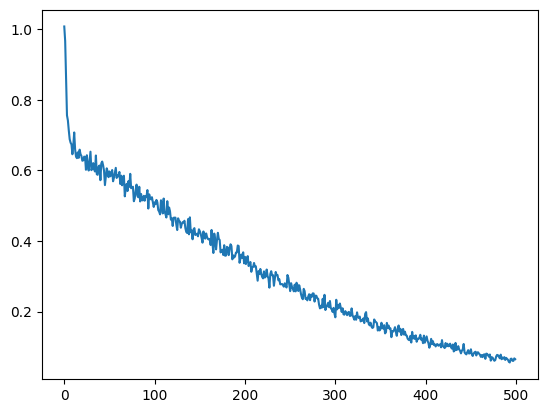

In [14]:
hidden_size = 256
encoder1 = EncoderRNN(input_lang.n_words, hidden_size).to(device)
attn_decoder1 = AttnDecoderRNN(hidden_size, output_lang.n_words, dropout_p=0.1).to(device)

trainIters(encoder1, attn_decoder1, 50000, print_every=3000)

In [15]:
def evaluate(encoder, decoder, sentence, max_length=MAX_LENGTH):
    with torch.no_grad():
        input_tensor = tensorFromSentence(input_lang, sentence)
        encoder_hidden = encoder.initHidden()

        encoder_outputs, encoder_hidden = encoder(input_tensor, encoder_hidden)

        decoder_input = torch.tensor([[SOS_token]], device=device)  # SOS

        decoder_hidden = encoder_hidden

        decoded_words = []
        decoder_attentions = []

        for di in range(max_length):
            decoder_output, decoder_hidden, decoder_attention = decoder(
                decoder_input, decoder_hidden, encoder_outputs)
            decoder_attentions.append(decoder_attention.squeeze(0).data)
            topv, topi = decoder_output.data.topk(1)
            if topi.squeeze().item() == EOS_token:
                decoded_words.append('<EOS>')
                break
            else:
                decoded_words.append(output_lang.index2word[topi.squeeze().item()])
            decoder_input = topi.detach().squeeze(1)

        return decoded_words, torch.cat(decoder_attentions)

In [16]:
def sentence_accuracy(pred_tokens, ref_tokens):
    # cắt theo độ dài nhỏ hơn
    min_len = min(len(pred_tokens), len(ref_tokens))
    correct = sum(1 for i in range(min_len) if pred_tokens[i] == ref_tokens[i])
    return correct / max(len(ref_tokens), 1)


In [17]:
from nltk.translate.bleu_score import sentence_bleu, SmoothingFunction

def evaluateRandomly(encoder, decoder, n=10):
    smoothie = SmoothingFunction().method4
    for i in range(n):
        pair = random.choice(pairs)
        print('Source:', pair[0])
        print('Reference:', pair[1])

        output_words, _ = evaluate(encoder, decoder, pair[0])
        output_sentence = ' '.join(output_words[:-1])

        print('Model:', output_sentence)

        # tokenized reference and hypothesis
        ref_tokens = pair[1].split()
        hyp_tokens = output_sentence.split()

        # Accuracy
        acc = sentence_accuracy(hyp_tokens, ref_tokens)
        # BLEU (nghiêng về n-gram, nên dùng smoothing cho câu ngắn)
        bleu = sentence_bleu([ref_tokens], hyp_tokens, smoothing_function=smoothie)

        print(f'Accuracy: {acc:.2f}, BLEU: {bleu:.2f}\n')


In [18]:
evaluateRandomly(encoder1, attn_decoder1)

Source: he is a clever boy .
Reference: es un noi despert .
Model: es un noi despert .
Accuracy: 1.00, BLEU: 1.00

Source: i was in the shower when the phone rang .
Reference: estava en la dutxa quan ha sonat el telefon .
Model: vaig pensar que en la llum .
Accuracy: 0.00, BLEU: 0.06

Source: what is going on ?
Reference: que passa ?
Model: que hi ha ?
Accuracy: 0.33, BLEU: 0.07

Source: dogs bark and birds tweet .
Reference: els gossos borden i les aus piulen .
Model: els ocells i escolta !
Accuracy: 0.12, BLEU: 0.03

Source: thanks !
Reference: gracies !
Model: gracies !
Accuracy: 1.00, BLEU: 0.22

Source: i hope that i can do it .
Reference: espere poder ho fer .
Model: espere poder ho fer .
Accuracy: 1.00, BLEU: 1.00

Source: i like walking .
Reference: m agrada caminar .
Model: m agrada caminar .
Accuracy: 1.00, BLEU: 1.00

Source: i need a stamp .
Reference: necessito un segell .
Model: necessito un segell .
Accuracy: 1.00, BLEU: 1.00

Source: i d like to meet your older sister .

input = your son is a genius .
output = el vostre fill es un fill . <EOS>


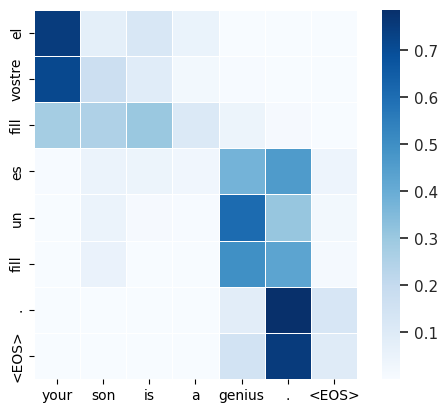

input = i can t remember which is my racket .
output = no puc recordar el meu fill . <EOS>


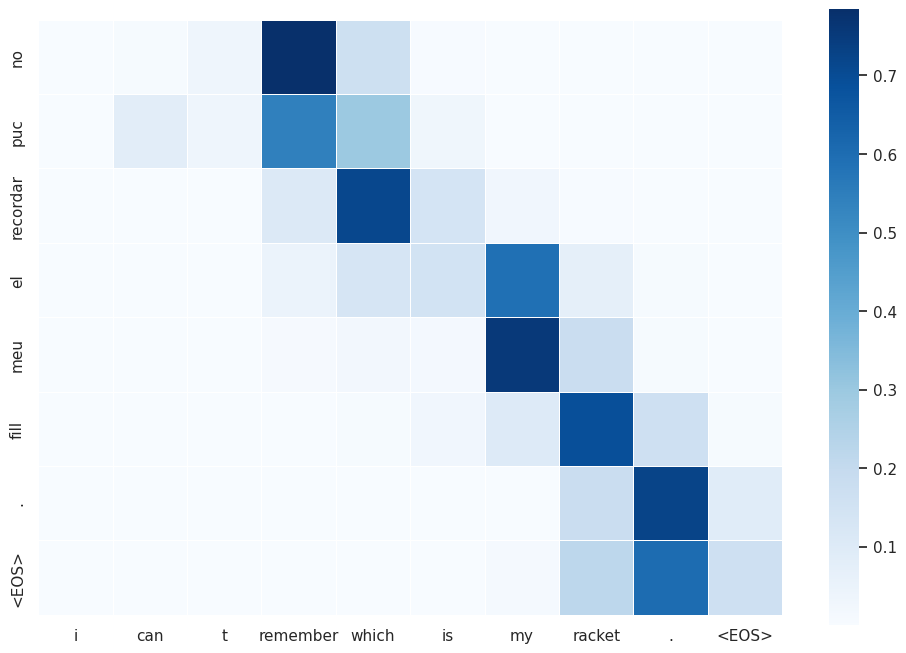

input = please circle the right answer .
output = sisplau mandi si us plau . <EOS>


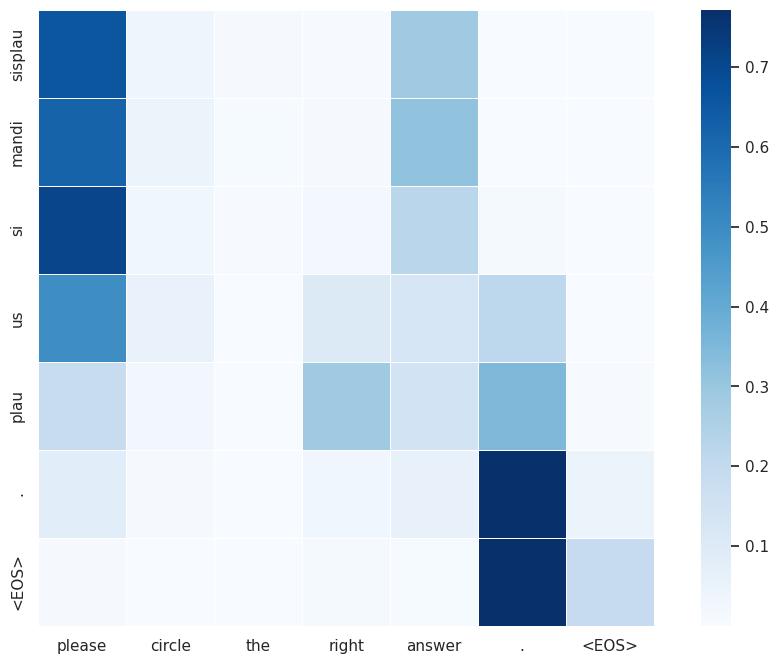

input = i d like to reserve a table for two .
output = m agradaria donar te un ou mes per a . <EOS>


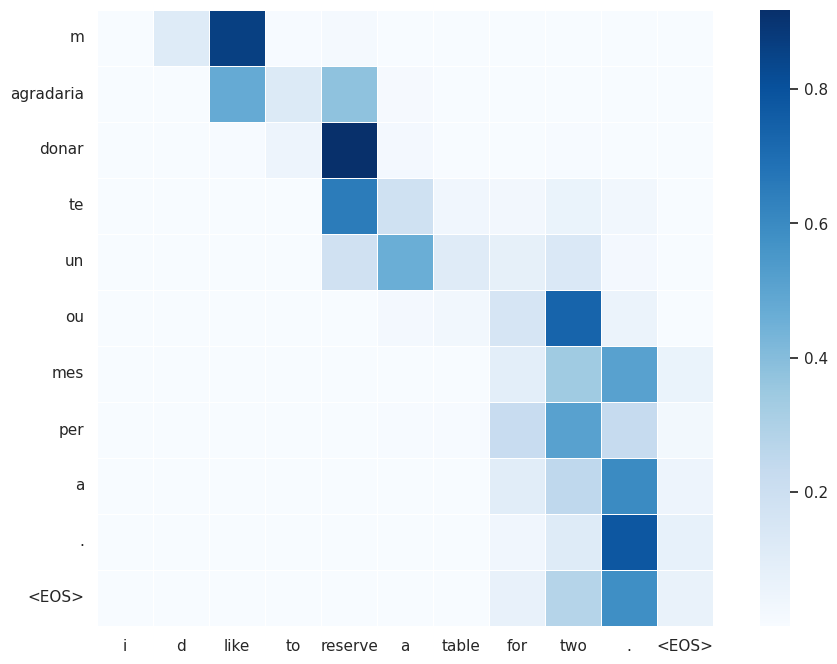

In [19]:
def showAttention(input_sentence, output_words, attentions):
    import pandas as pd
    # Set up figure with colorbar
    fig = plt.figure()
    ax = fig.add_subplot(111)
    #cax = ax.matshow(attentions.numpy(), cmap='Blues')
    #fig.colorbar(cax)
    sns.set(rc={'figure.figsize':(12, 8)})
    input_sentence_list = input_sentence.split(' ') + ['<EOS>']

    df = pd.DataFrame(attentions, columns = input_sentence_list, index = output_words)
    ax = sns.heatmap(
        df.astype(float),
        linewidth=0.5,
        cmap="Blues",
        square=True)


    plt.show()


def evaluateAndShowAttention(input_sentence):
    output_words, attentions = evaluate(
        encoder1, attn_decoder1, input_sentence)
    print('input =', input_sentence)
    print('output =', ' '.join(output_words))
    showAttention(input_sentence, output_words, attentions.detach().cpu())


evaluateAndShowAttention("your son is a genius .")

evaluateAndShowAttention("i can t remember which is my racket .")

evaluateAndShowAttention("please circle the right answer .")

evaluateAndShowAttention("i d like to reserve a table for two .")
